# PRINT footprints in PBMCs

A transcription factor bound to DNA protects a short stretch from Tn5, so
the cut track shows a dip where the factor sits.
[PRINT](https://www.nature.com/articles/s41586-024-08443-4) (Hu *et al.*,
*Nature* 2025) tests, at every base and at footprint sizes from 4 to 200 bp,
whether Tn5 cut a window less often than its sequence bias predicts.
Small footprints are transcription factors; large ones are nucleosomes.
[scPrinter](https://github.com/buenrostrolab/scPrinter) brought PRINT to
single-cell data and added a model that turns the footprint around a site
into a binding probability.

This tutorial follows scPrinter's
[PBMC tutorial](https://ruochiz.com/scprinter_doc/tutorials/PBMC_scATAC_tutorial.html)
on measured cuts:

1. group PBMCs into seven cell types;
2. look at multi-scale footprints at the promoters of marker genes;
3. score TF binding at motif sites and compare cell types, one factor at a time.

```python
bias = epi.tl.tn5_bias(genome)                                    # PRINT's Tn5 bias CNN
fp   = epi.tl.multi_scale_footprint_region(adata, sites, groupby=..., bias=bias)
tfbs = epi.tl.tf_binding_score(adata, peaks, groupby=..., bias=bias, sites=motif_sites)
```

The data are the 10x Genomics PBMC 10k Multiome sample (ATAC part), with the
Seurat-WNN cell types that scGLUE distributes with it. The genome is hg38.
[seq2PRINT](t_seq2print.ipynb) uses the same sample and cell types and
predicts these footprints from DNA sequence instead of reading them from cuts.

## Part 1 · Setup

In [1]:
%matplotlib inline
import os, sys, pathlib, re, gzip, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anndata as ad
import pysam
import warnings
warnings.filterwarnings('ignore', module='tqdm')
warnings.filterwarnings('ignore', category=FutureWarning)


def _find_repo(start):  # works from the source tree or a pip install
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import epione as epi

# Downloaded and checked against pinned sha256 sums on first use (2.6 GB).
# EPIONE_TUTORIAL_DATA picks the folder; the default is epione's pooch cache.
DATA = os.environ.get('EPIONE_TUTORIAL_DATA')
files = epi.datasets.pbmc10k_multiome_atac(pathlib.Path(DATA) / 'pbmc10k_multiome' if DATA else None)
FASTA = epi.data.hg38.fasta          # GENCODE v41 GRCh38, downloaded once
GFF = epi.data.hg38.annotation       # GENCODE v41 basic annotation, for TSSs
print(sorted(files))

epi.pl.plot_set()
# One colour per cell type, from epi.pl.sc_color, used in every figure.
ORDER = ['CD14 Mono', 'CD16 Mono', 'DC', 'B', 'CD4 T', 'CD8 T', 'NK']
COLOR = dict(zip(ORDER, ['#EF7B77', '#941456', '#FCBC10', '#279AD7', '#368650', '#7CBB5F', '#5E4D9A']))
assert all(c in epi.pl.sc_color for c in COLOR.values())


def restyle(fig, tracks=(), groups=(), fontsize=12):
    # epi.pl's PRINT plots draw in a light theme of their own (grey ticks,
    # open frames, their own group colours). This puts them back in the
    # plot_set() look: black frames and text, cell types in COLOR.
    for ax in fig.axes:
        if ax.get_label() != '<colorbar>':
            for sp in ax.spines.values():
                sp.set_visible(True); sp.set_color('k')
            ax.grid(False)
        ax.tick_params(colors='k', labelsize=fontsize - 1)
        for lab in (ax.xaxis.label, ax.yaxis.label):
            lab.set_color('k'); lab.set_fontsize(fontsize)
        for t in ax.texts:
            t.set(color='k', fontsize=fontsize - 1, fontweight='normal')
    for ax, g in zip(tracks, groups):
        ax.collections[0].set_facecolor(COLOR[g])            # the filled cut track
    if fig._suptitle is not None:
        fig._suptitle.set(color='k', fontweight='normal', fontsize=fontsize + 2)

['atac', 'fragments', 'fragments_index', 'peaks']


└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Part 2 · Cells and cell types

A footprint is a shortage of cuts, so it takes many cuts to see one. We
therefore pool cells into seven coarse types and footprint each pool
(a pseudobulk). MAIT, γδ T cells and HSPCs are left out: they are small and
do not fit one of the seven groups cleanly.

In [2]:
COARSE = {'CD14 Mono': 'CD14 Mono', 'CD16 Mono': 'CD16 Mono', 'cDC': 'DC', 'pDC': 'DC',
          'Naive B': 'B', 'Intermediate B': 'B', 'Memory B': 'B', 'Plasma': 'B',
          'CD4 Naive': 'CD4 T', 'CD4 TCM': 'CD4 T', 'CD4 TEM': 'CD4 T', 'Treg': 'CD4 T',
          'CD8 Naive': 'CD8 T', 'CD8 TEM_1': 'CD8 T', 'CD8 TEM_2': 'CD8 T', 'NK': 'NK'}
full = ad.read_h5ad(files['atac'])                       # cells x peaks, with obs['cell_type']
full.obs['group'] = pd.Categorical(full.obs['cell_type'].astype(str).map(COARSE), categories=ORDER)
full = full[full.obs['group'].notna()].copy()

# PRINT reads cuts from the fragments file, so the AnnData only needs the
# cell barcodes, the grouping and where the fragments are.
adata = ad.AnnData(obs=full.obs[['cell_type', 'group']].copy())
adata.uns['files'] = {'fragments': str(files['fragments'])}
fa = pysam.FastaFile(str(FASTA))
adata.uns['reference_sequences'] = {c: fa.get_reference_length(c) for c in fa.references
                                    if re.fullmatch(r'chr[0-9XY]+', c)}
print(f'{adata.n_obs:,} cells in {adata.obs.group.nunique()} types')

9,341 cells in 7 types


In [3]:
%%time
# Fragments per cell: one pass over the fragments file.
n = pd.Series(0, index=adata.obs_names)
for chunk in pd.read_csv(files['fragments'], sep='\t', comment='#', header=None, usecols=[3],
                         names=['bc'], dtype={'bc': 'category'}, chunksize=20_000_000):
    vc = chunk['bc'].value_counts()
    n += vc.reindex(n.index, fill_value=0)
adata.obs['n_fragments'] = n.astype(int)

by = adata.obs.groupby('group', observed=True)
types = pd.DataFrame({
    'Seurat types': by['cell_type'].agg(lambda s: ', '.join(sorted(s.astype(str).unique()))),
    'cells': by.size(),
    'fragments (M)': (by['n_fragments'].sum() / 1e6).round(1),
    'median per cell': by['n_fragments'].median().astype(int),
})
types

CPU times: user 2min 13s, sys: 2.87 s, total: 2min 15s
Wall time: 2min 15s


,Seurat types,cells,fragments (M),median per cell
group,,,,
CD14 Mono,CD14 Mono,2554,51.4,19400
CD16 Mono,CD16 Mono,442,7.8,17791
DC,"cDC, pDC",278,7.4,26607
B,"Intermediate B, Memory B, Naive B, Plasma",735,14.9,20261
CD4 T,"CD4 Naive, CD4 TCM, CD4 TEM, Treg",2938,47.9,16399
CD8 T,"CD8 Naive, CD8 TEM_1, CD8 TEM_2",1991,33.2,16997
NK,NK,403,6.6,16357


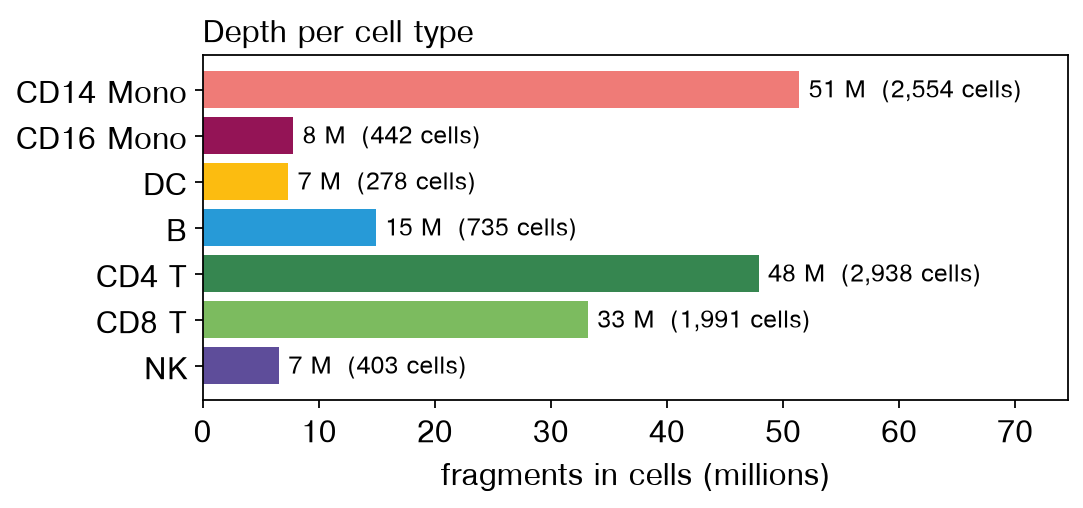

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(types.index[::-1], types['fragments (M)'][::-1], color=[COLOR[g] for g in types.index[::-1]])
for y, (g, v) in enumerate(types['fragments (M)'][::-1].items()):
    ax.text(v + 0.8, y, f'{v:.0f} M  ({types.cells[g]:,} cells)', va='center', fontsize=11)
ax.set_xlabel('fragments in cells (millions)')
ax.set_xlim(0, types['fragments (M)'].max() * 1.45)
ax.grid(False)
ax.set_title('Depth per cell type', loc='left')
plt.tight_layout(); plt.show()

CD14 monocytes and CD4 T cells have about 50 M fragments each, comparable to
a deep bulk ATAC-seq library. B cells have about a third of that, and the
three small types under 10 M. Keep the depth in mind when comparing types:
a footprint in a shallow type has fewer cuts behind it.

## Part 3 · Tn5 bias and the footprint null

Tn5 prefers some sequences, so a dip in cuts only means something relative
to what the sequence predicts. `epi.tl.tn5_bias` returns PRINT's bias CNN,
run on demand on the bases asked for (the model is 0.1 MB). PRINT's learned
null, the "dispersion model", says how much cut counts vary around that
expectation; it is loaded once and passed to every call below.

In [5]:
# exact=False runs the CNN on each window as asked. exact=True instead
# replays scPrinter's genome-wide chunking so the bias matches scPrinter's
# to the last bit; it differs only by float rounding and is slower.
bias = epi.tl.tn5_bias(FASTA, exact=False)         # PRINT CNN (downloads 0.1 MB once)
dispersion = epi.tl.DispersionModel.load()         # PRINT's learned null (0.7 MB, once)
print('predicted Tn5 bias, 20 bp of the SPI1 promoter:', bias.track('chr11', 47_378_530, 47_378_550).round(2))

predicted Tn5 bias, 20 bp of the SPI1 promoter: [0.02 2.39 0.09 2.89 0.14 0.05 0.05 0.05 0.13 0.9  0.71 0.03 0.04 0.01
 0.04 0.48 0.32 0.03 0.01 0.06]


## Part 4 · Footprints at marker-gene promoters

scPrinter's PBMC tutorial looks at the promoters of marker genes. We take
four of them: *SPI1* (PU.1; expressed in monocytes and B cells), *CD14*
(monocytes), *CD79A* (B cells) and *CD3D* (T cells). Each window is centred
on the gene's TSS from GENCODE and turned to the direction of transcription
(passing `strand` does that), so negative positions are upstream. The cut
counts give a first view: a promoter is open in a cell type when it
collects many cuts there.

In [6]:
GENES = {'SPI1': 'monocytes, B', 'CD14': 'monocytes', 'CD79A': 'B cells', 'CD3D': 'T cells'}

# TSS of each gene from the GENCODE annotation (0-based).
rows = []
with gzip.open(GFF, 'rt') as fh:
    for line in fh:
        if '\tgene\t' not in line:
            continue
        f = line.split('\t')
        name = re.search(r'gene_name=([^;]+)', f[8]).group(1)
        if name in GENES:
            rows.append((name, GENES[name], f[0], int(f[3]) - 1 if f[6] == '+' else int(f[4]) - 1, f[6]))
LOCI = pd.DataFrame(rows, columns=['gene', 'marker of', 'chrom', 'TSS', 'strand']).set_index('gene').loc[list(GENES)]

# Read +-600 bp, show +-400 bp: near the edges the large footprints lack flanks.
fps = {g: epi.tl.multi_scale_footprint_region(
           adata, [{'chrom': r.chrom, 'center': r.TSS, 'strand': r.strand}], groupby='group',
           bias=bias, dispersion=dispersion, flank=600, verbose=False)
       for g, r in LOCI.iterrows()}

inner = np.abs(fps['SPI1'].positions) <= 400
cuts = pd.DataFrame({g: dict(zip(fp.groups, fp.insertions[:, inner].sum(1).astype(int)))
                     for g, fp in fps.items()}).T[ORDER]
pd.concat([LOCI, cuts], axis=1)

,marker of,chrom,TSS,strand,CD14 Mono,CD16 Mono,DC,B,CD4 T,CD8 T,NK
SPI1,"monocytes, B",chr11,47378546,-,1904,302,207,678,74,74,29
CD14,monocytes,chr5,140633699,-,930,84,41,32,96,72,6
CD79A,B cells,chr19,41877278,+,293,31,66,1402,255,212,21
CD3D,T cells,chr11,118342704,-,32,4,4,15,983,702,13


Each promoter is open where the gene is expressed. Within 400 bp of the
TSS, *CD14* collects 930 cuts in CD14 monocytes and fewer than 100 in every
other type; *CD79A* 1,402 in B cells and at most 293 elsewhere; *CD3D* 983
and 702 in CD4 and CD8 T cells and at most 32 elsewhere. *SPI1* is open in
CD14 monocytes (1,904 cuts), B cells (678), CD16 monocytes (302) and DCs
(207), and nearly closed in T and NK cells (74 or fewer).

The footprint plots below show four cell types for each promoter. Above
each heatmap is the evidence it rests on: cuts observed in that type
(filled) and cuts the bias predicts (dashed, rescaled to the same total).
Footprints are where the filled track falls below the dashed one. In the
heatmap they show up as dark spots: small ones (under about 50 bp) are the
size of a bound TF, broad ones at 100-200 bp the size of a nucleosome. The
dotted line is the TSS. Panels with fewer than 300 cuts are greyed out:
with so few cuts a short empty stretch can already look significant, so
those heatmaps are noise.

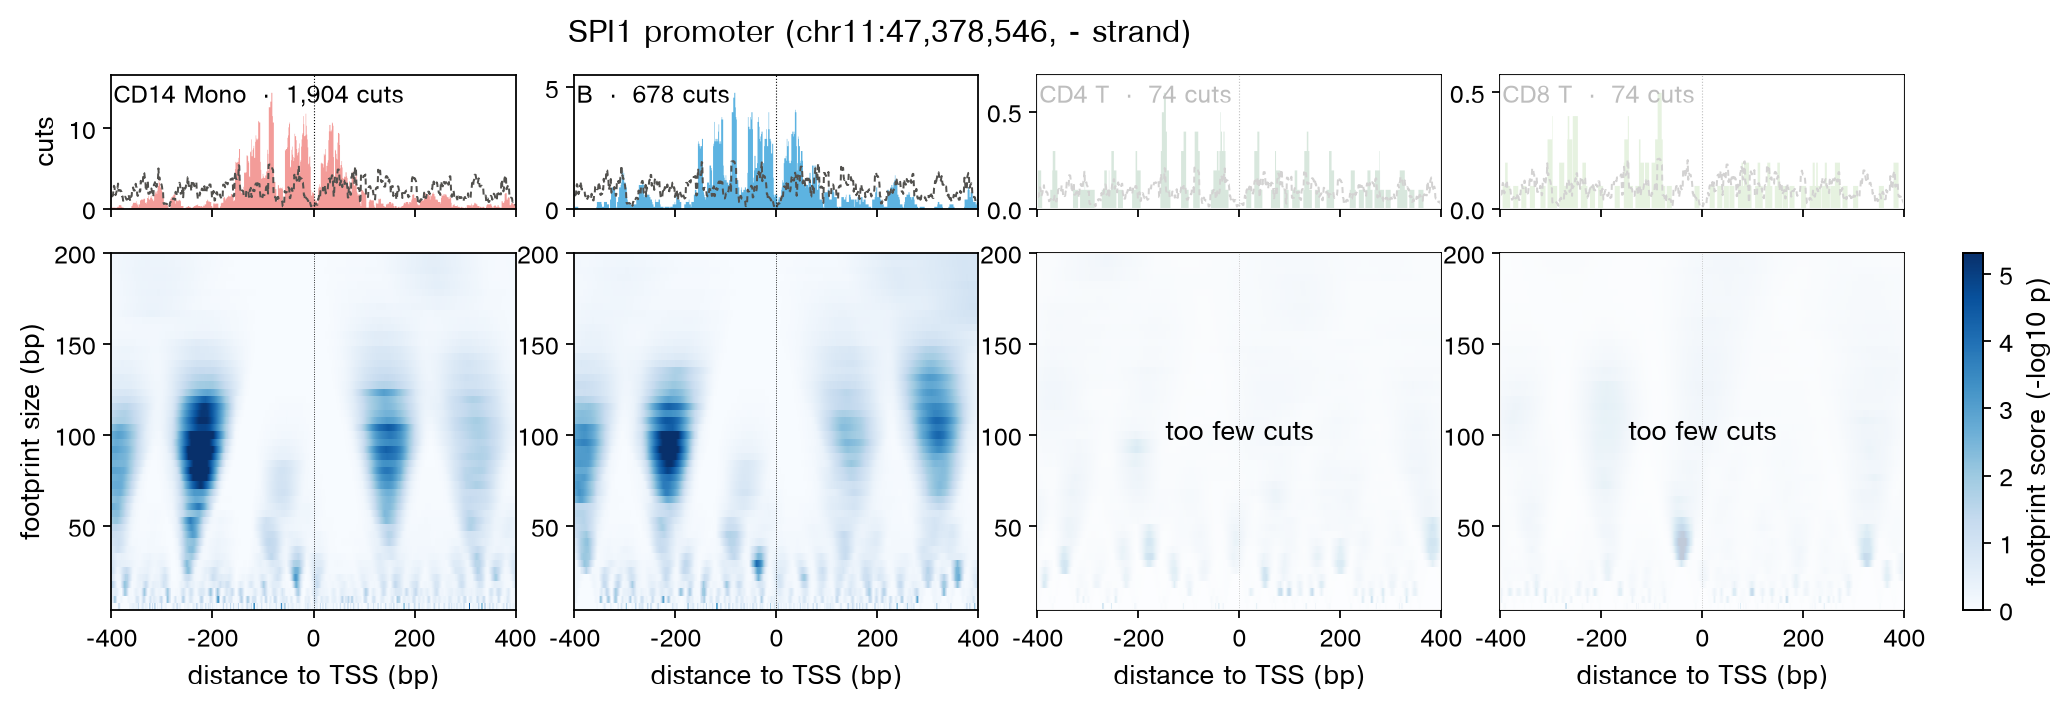

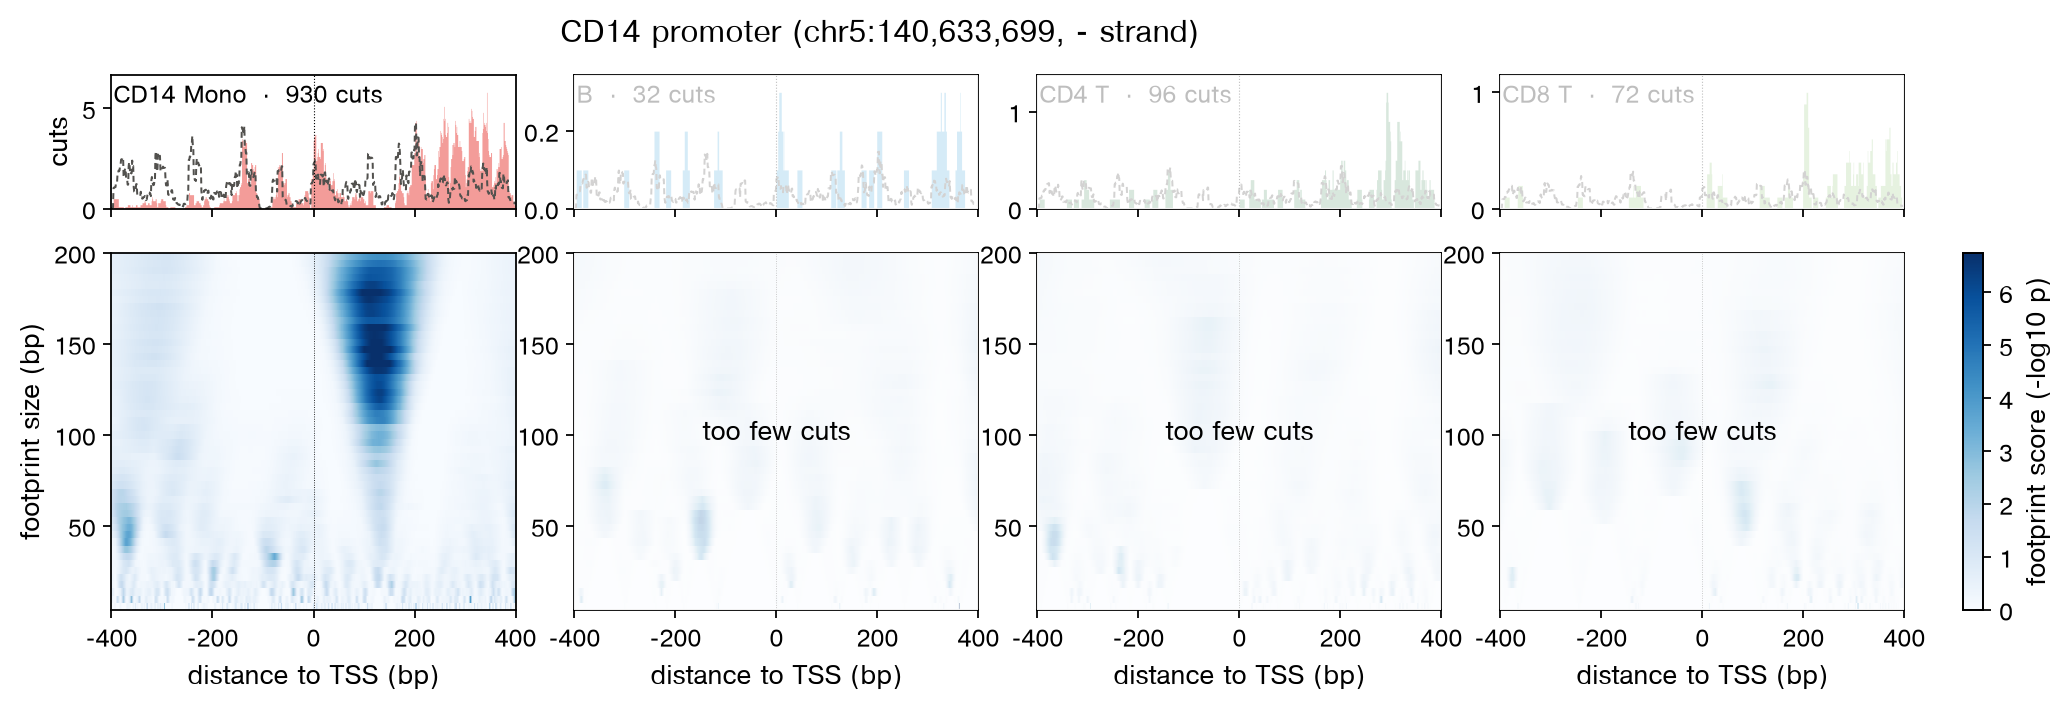

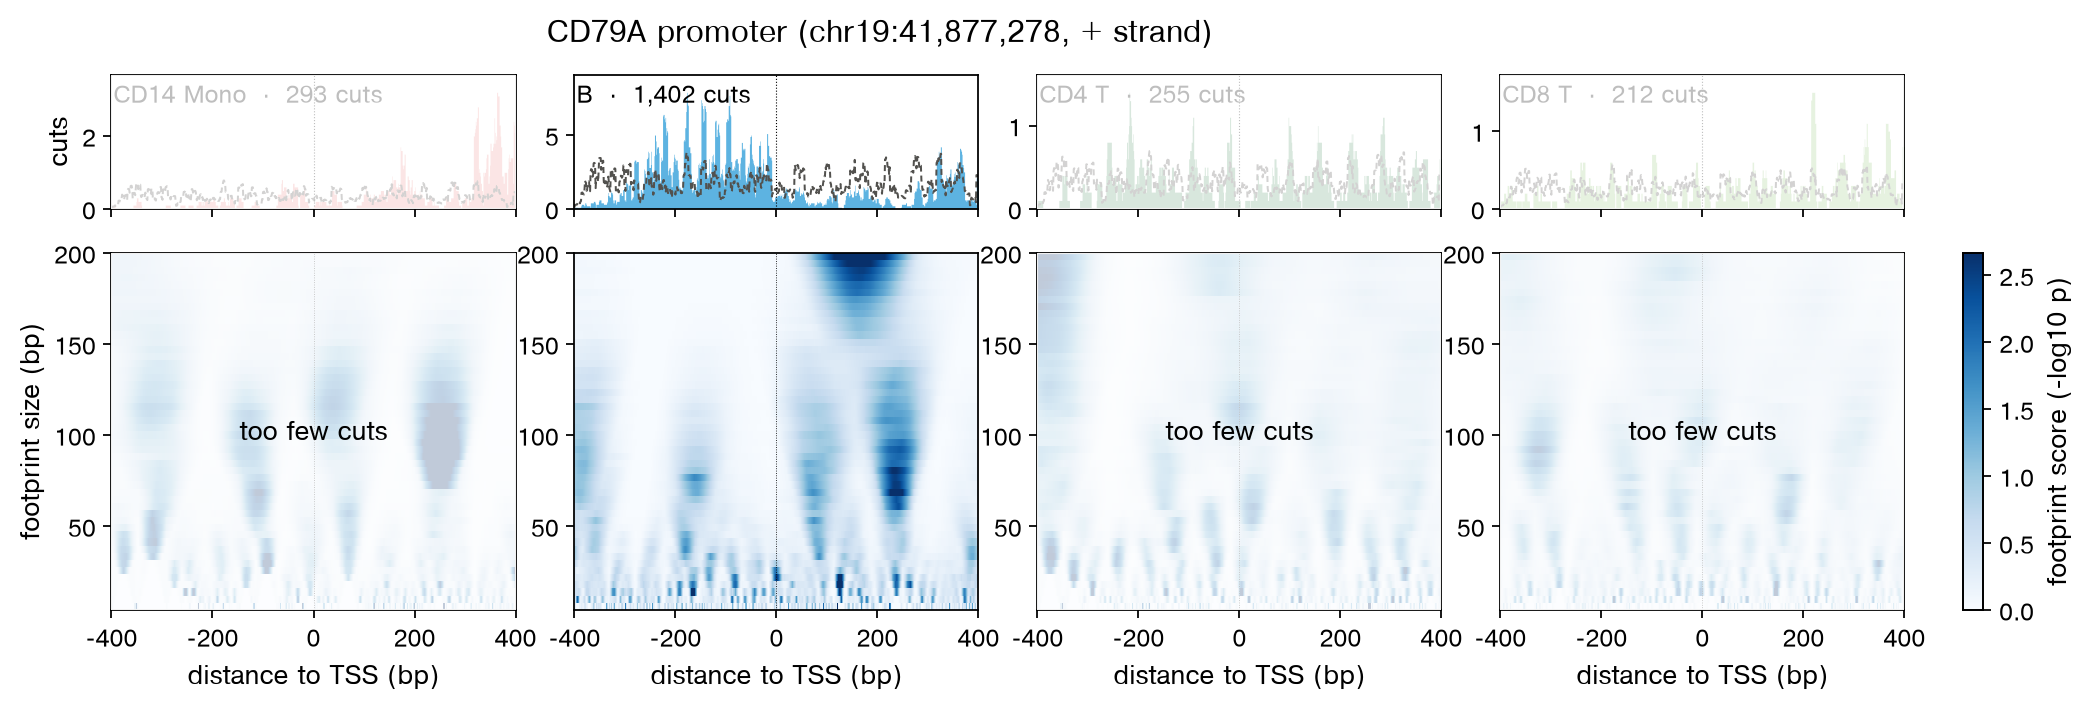

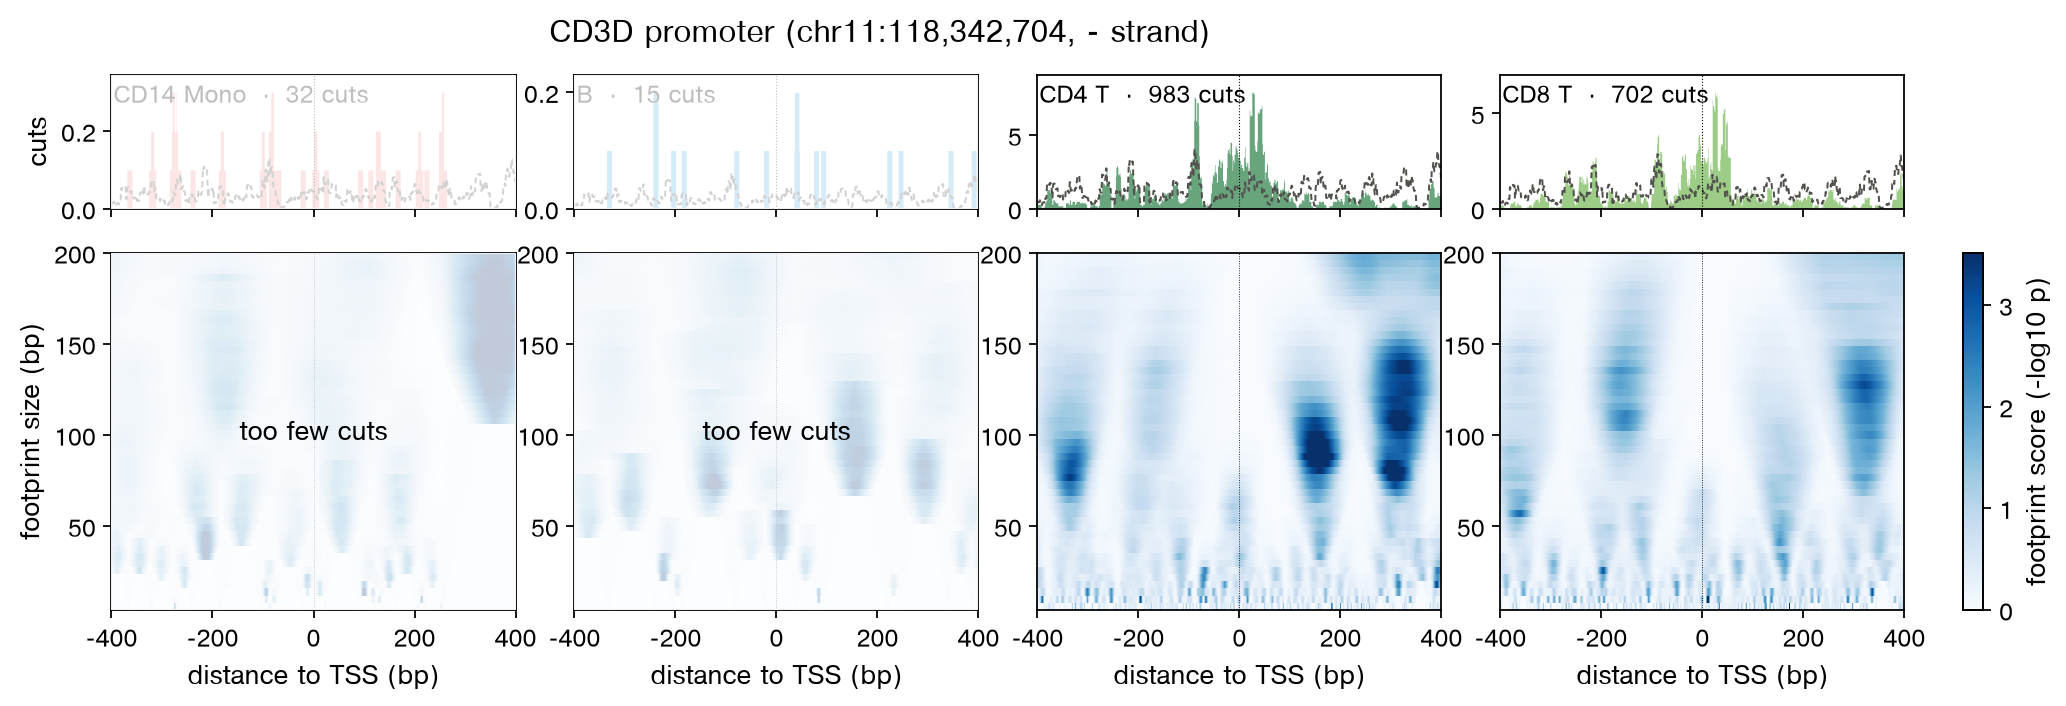

In [7]:
SHOW = ['CD14 Mono', 'B', 'CD4 T', 'CD8 T']
MIN_CUTS = 300


def show_footprint(gene, groups=SHOW):
    fp, r = fps[gene], LOCI.loc[gene]
    i = [fp.groups.index(g) for g in groups]
    n = fp.insertions[i][:, inner].sum(1)
    ok = [i[k] for k in range(len(groups)) if n[k] >= MIN_CUTS]
    vmax = np.nanpercentile(fp.score[ok][..., inner], 99.5)   # colour scale from the usable panels
    fig, axes = epi.pl.plot_multi_scale_footprint_region(
        fp, groups=groups, order=groups, ncols=len(groups), zoom=400, vmax=vmax,
        show=False, figsize=(3.6 * len(groups) + 0.6, 4.4),
        title=f'{gene} promoter ({r.chrom}:{r.TSS:,}, {r.strand} strand)')
    restyle(fig, tracks=fig.track_axes, groups=groups)
    for k, (hax, tax) in enumerate(zip(axes, fig.track_axes)):
        hax.set_xlabel('distance to TSS (bp)')
        tax.axvline(0, color='k', lw=0.5, ls=':')
        if n[k] < MIN_CUTS:
            for ax in (hax, tax):
                ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes,
                                           color='white', alpha=0.75, zorder=5))
            hax.text(0.5, 0.5, 'too few cuts', transform=hax.transAxes, ha='center',
                     va='center', fontsize=12, zorder=6)
    fig.track_axes[0].set_ylabel('cuts', fontsize=12)
    fig.axes[-1].set_ylabel('footprint score (−log10 p)', fontsize=12)    # the colorbar
    plt.show()


for gene in GENES:
    show_footprint(gene)

To put numbers on the heatmaps, the next table lists, for every cell type
with enough cuts, the strongest TF-sized footprint (10-40 bp) and the
strongest nucleosome-sized one (100-200 bp), with their position relative
to the TSS.

In [8]:
rows = []
for gene, fp in fps.items():
    pos, size = fp.positions[inner], 2 * fp.scales
    for g in ORDER:
        if cuts.loc[gene, g] < MIN_CUTS:
            continue
        S = fp.score[fp.groups.index(g)][:, inner]
        row = {'gene': gene, 'cell type': g, 'cuts': cuts.loc[gene, g]}
        for label, m in (('TF-sized', (size >= 10) & (size <= 40)), ('nucleosome-sized', size >= 100)):
            si, pi = np.unravel_index(np.nanargmax(S[m]), S[m].shape)
            row[(label, 'position')] = int(pos[pi])
            row[(label, 'size')] = int(size[m][si])
            row[(label, '−log10 p')] = round(float(S[m][si, pi]), 1)
        rows.append(row)
n_tf = ((size >= 10) & (size <= 40)).sum() * inner.sum()
print(f'each heatmap has {n_tf:,} TF-sized (size, position) cells')
peaks_at_tss = pd.DataFrame(rows).set_index(['gene', 'cell type', 'cuts'])
peaks_at_tss.columns = pd.MultiIndex.from_tuples(peaks_at_tss.columns)
peaks_at_tss

each heatmap has 6,408 TF-sized (size, position) cells


TF-sized               nucleosome-sized              
                     position size −log10 p         position size −log10 p
gene  cell type cuts                                                      
SPI1  CD14 Mono 1904      -35   20      3.2             -222  100      6.8
      CD16 Mono 302       322   16      5.2              166  100      2.7
      B         678       -40   28      4.1             -206  100      6.2
CD14  CD14 Mono 930      -370   40      3.7              127  148      7.8
CD79A B         1402     -164   12      4.4              170  200      3.7
CD3D  CD4 T     983       391   16      3.2              319  108      4.1
      CD8 T     702       337   12      3.1              322  128      3.2

What the heatmaps show:

* **SPI1.** CD14 monocytes and B cells give nearly the same picture,
  although they share no cells: a 100-bp footprint about 210 bp upstream of
  the TSS (−222 and −206) and a TF-sized footprint about 40 bp upstream
  (−35 and −40). Both types express PU.1. CD16 monocytes, with 302 cuts,
  just pass the cut-off and do not reproduce the pattern.
* **CD14.** Only CD14 monocytes have enough cuts. The strongest footprint
  is 148 bp wide and centred 127 bp downstream of the annotated TSS, a
  stretch with few cuts between the TSS and the open region further
  downstream. Its size and place fit a positioned nucleosome.
* **CD79A.** In B cells the strongest footprint is nucleosome-sized
  (200 bp, 170 bp downstream of the TSS).
* **CD3D.** CD4 and CD8 T cells, scored separately, both have a large
  footprint about 320 bp downstream of the TSS (+319 and +322).

So one promoter with a few hundred to two thousand cuts shows its
nucleosome-sized structure, and the structure repeats between related cell
types. TF-sized footprints at a single promoter are weak: their best scores
are 3-4 (p = 10⁻³-10⁻⁴), and each heatmap has 6,408 TF-sized
(size, position) cells, so scores of that size also turn up by chance.
scPrinter's tutorial uses seq2PRINT, which denoises footprints, for single
loci. On measured cuts, TF binding is better judged over many sites of one
motif, which is what Part 5 does.

## Part 5 · TF binding at motif sites, compared between cell types

A single promoter has few cuts per base. Pooling evidence over many sites
is more robust: we score every motif site of a factor in the peaks and
compare two cell types site by site, as scPrinter does.

> **A note on the score.** PRINT's binding score is not Epione's default
> per-site score: `epi.tl.tf_binding` (`method='occupancy'`, see
> [t_tf_binding](t_tf_binding.ipynb)) ranked ChIP-bound sites better on ENCODE
> data and runs faster. PRINT's score is the one to use for footprint shapes
> and for comparisons with scPrinter; it reproduces scPrinter's numbers
> (`tests/test_print.py`).

**Peaks.** The ATAC peaks of this sample with at least 1,000 cuts in total,
on the autosomes and chrX, and at most 3 kb wide. Peaks shorter than 1 kb
are widened to 1 kb around their centre, because PRINT needs 100 bp of
context on each side of a site.

**Motif sites.** JASPAR 2024 motifs of six factors, matched with MOODS at a
false-positive rate of 5 × 10⁻⁵ (`epi.tl.hint_match_motifs`): CEBPA
(monocytes), SPI1 (PU.1; monocytes and B cells), PAX5 and EBF1 (B cells),
RUNX3 (T and NK cells), and CTCF, which binds in every cell type and serves
as a control.

In [9]:
var = full.var
width = var.chromEnd - var.chromStart
keep = ((var.n_counts >= 1000) & (width <= 3000)
        & var.chrom.isin([f'chr{i}' for i in range(1, 23)] + ['chrX']))
mid = (var.chromStart + var.chromEnd)[keep] // 2
peaks = pd.DataFrame({'chrom': var.chrom[keep],
                      'start': np.minimum(var.chromStart[keep], mid - 500),
                      'end': np.maximum(var.chromEnd[keep], mid + 500)}).reset_index(drop=True)
print(f'{len(peaks):,} of {len(var):,} peaks kept, {(peaks.end - peaks.start).sum() / 1e6:.0f} Mb')

from pyjaspar import jaspardb
JASPAR = {'CEBPA': 'MA0102.5', 'SPI1': 'MA0080.7', 'PAX5': 'MA0014.4',
          'EBF1': 'MA0154.5', 'RUNX3': 'MA0684.3', 'CTCF': 'MA0139.2'}
jdb = jaspardb(release='JASPAR2024')
pfm = {tf: np.array([jdb.fetch_motif_by_id(mid).counts[b] for b in 'ACGT'])
       for tf, mid in JASPAR.items()}
hits = epi.tl.hint_match_motifs(peaks, pfm, FASTA, fpr=5e-5)
# palindromic motifs match both strands at one position: keep the better strand
hits = (hits.sort_values('score', ascending=False)
            .drop_duplicates(['name', 'chrom', 'start'])
            .sort_values(['chrom', 'start']).reset_index(drop=True))
hits['center'] = (hits.start + hits.end) // 2
hits.groupby('name').size().rename('motif sites').to_frame().T[list(JASPAR)]

21,420 of 107,194 peaks kept, 38 Mb


name,CEBPA,SPI1,PAX5,EBF1,RUNX3,CTCF
motif sites,5703,23457,1712,9999,6238,12462


### Depth first

`tf_binding_score` computes each peak's footprints at the six sizes PRINT's
binding model reads, then scores the 201-bp multi-scale footprint around
every site; each score is a probability of binding. Before comparing cell
types, check how the score depends on depth. CTCF binds its sites in every
blood cell type, so its scores should not differ much between types. We
score the CTCF sites in all seven types at their full depth:

In [10]:
%%time
def scores_at(adata, sites, groupby='group'):
    # PRINT binding probabilities of `sites` (a slice of `hits`), one column per group.
    # Only the peaks with a site at least 100 bp from their edges are read.
    has = np.zeros(len(peaks), dtype=bool)
    for c, idx in peaks.groupby('chrom').groups.items():
        cen = np.sort(sites.center[sites.chrom == c].to_numpy())
        p = peaks.loc[idx]
        has[idx] = (np.searchsorted(cen, p.end - 100, side='right')
                    > np.searchsorted(cen, p.start + 100, side='right'))
    reg = peaks[has]
    res = epi.tl.tf_binding_score(adata, reg, groupby=groupby, bias=bias, dispersion=dispersion,
                                  sites=sites[['chrom', 'start', 'end', 'strand']],
                                  keep_tracks=False, verbose=False)
    # attach the scores to the motif table; a site is reported at its centre
    score = pd.DataFrame(res.score.T, columns=res.groups)
    scored = (pd.concat([res.sites[['chrom', 'center', 'strand']], score], axis=1)
                .drop_duplicates(['chrom', 'center', 'strand']))
    return sites.merge(scored, on=['chrom', 'center', 'strand'])


ctcf = scores_at(adata, hits[hits.name == 'CTCF'])
pd.DataFrame({'fragments (M)': types['fragments (M)'],
              'median CTCF binding probability': ctcf[ORDER].median().round(3)}).T

CPU times: user 58min 19s, sys: 6.78 s, total: 58min 26s
Wall time: 3min 53s


,CD14 Mono,CD16 Mono,DC,B,CD4 T,CD8 T,NK
fragments (M),51.400,7.800,7.40,14.900,47.90,33.200,6.600
median CTCF binding probability,0.362,0.143,0.19,0.244,0.36,0.336,0.124


The median CTCF score follows depth, not cell type: 0.36 in CD14
monocytes (51 M fragments) and CD4 T cells (48 M), 0.34 in CD8 T cells
(33 M), 0.24 in B cells (15 M), and 0.12-0.19 in the three types with 7-8 M
fragments. A footprint is a significant shortage of cuts, and the same
shortage is more significant when more cuts stand behind it. At full depth,
every factor would look less bound in B cells than in T cells.

So we compare cell types at equal depth. We take the four types with at
least 15 M fragments (CD14 monocytes, B cells, CD4 and CD8 T cells) and
draw random cells from each until it has as many fragments as the B cells.

In [11]:
target = adata.obs.loc[adata.obs.group == 'B', 'n_fragments'].sum()
rng = np.random.default_rng(0)
picked = []
for g in ['CD14 Mono', 'B', 'CD4 T', 'CD8 T']:
    o = adata.obs[adata.obs.group == g]
    o = o.iloc[rng.permutation(len(o))]
    picked += list(o.index[o.n_fragments.cumsum() <= target])
matched = adata[picked].copy()
matched.obs['group'] = matched.obs['group'].cat.remove_unused_categories()
matched.obs.groupby('group', observed=True)['n_fragments'].agg(cells='size', fragments='sum')

,cells,fragments
group,,
CD14 Mono,726,14854425
B,735,14875106
CD4 T,914,14868275
CD8 T,884,14872616


Now every motif site, in the four depth-matched pseudobulks. This is the
slow step of the tutorial (about 8 minutes with 16 CPU cores).

In [12]:
%%time
sites = scores_at(matched, hits)
SHOW4 = ['CD14 Mono', 'B', 'CD4 T', 'CD8 T']
print(f'{len(sites):,} of {len(hits):,} motif sites scored (the rest lie within 100 bp of a peak edge)')
sites.groupby('name')[SHOW4].median().round(3).loc[list(JASPAR)]

55,434 of 59,571 motif sites scored (the rest lie within 100 bp of a peak edge)
CPU times: user 2h 8min 32s, sys: 16.5 s, total: 2h 8min 48s
Wall time: 8min 24s


,CD14 Mono,B,CD4 T,CD8 T
name,,,,
CEBPA,0.207,0.036,0.036,0.036
SPI1,0.194,0.076,0.045,0.045
PAX5,0.120,0.115,0.094,0.097
EBF1,0.060,0.058,0.048,0.051
RUNX3,0.059,0.047,0.055,0.058
CTCF,0.226,0.244,0.242,0.248


At equal depth the CTCF control is flat: its median is 0.226-0.248 in
all four types. CEBPA sites score 0.207 in CD14 monocytes and 0.036 in each
of the other three types. SPI1 sites score 0.194 in monocytes, 0.076 in B
cells and 0.045 in T cells. 0.036 is what the binding model returns for a
window with no footprint at all, so the typical CEBPA site in B and T cells
shows no footprint. PAX5, EBF1 and RUNX3 have low medians in every type
(0.05-0.12) that differ little between types; PAX5 sites even score
slightly higher in monocytes (0.120) than in B cells (0.115).

Now the site-by-site comparisons. Each dot is one motif site; its position
is the binding probability in the two cell types. Sites above the diagonal
are scored higher in the type on the y-axis. The numbers in the corners
count sites with a difference larger than 0.1 either way.

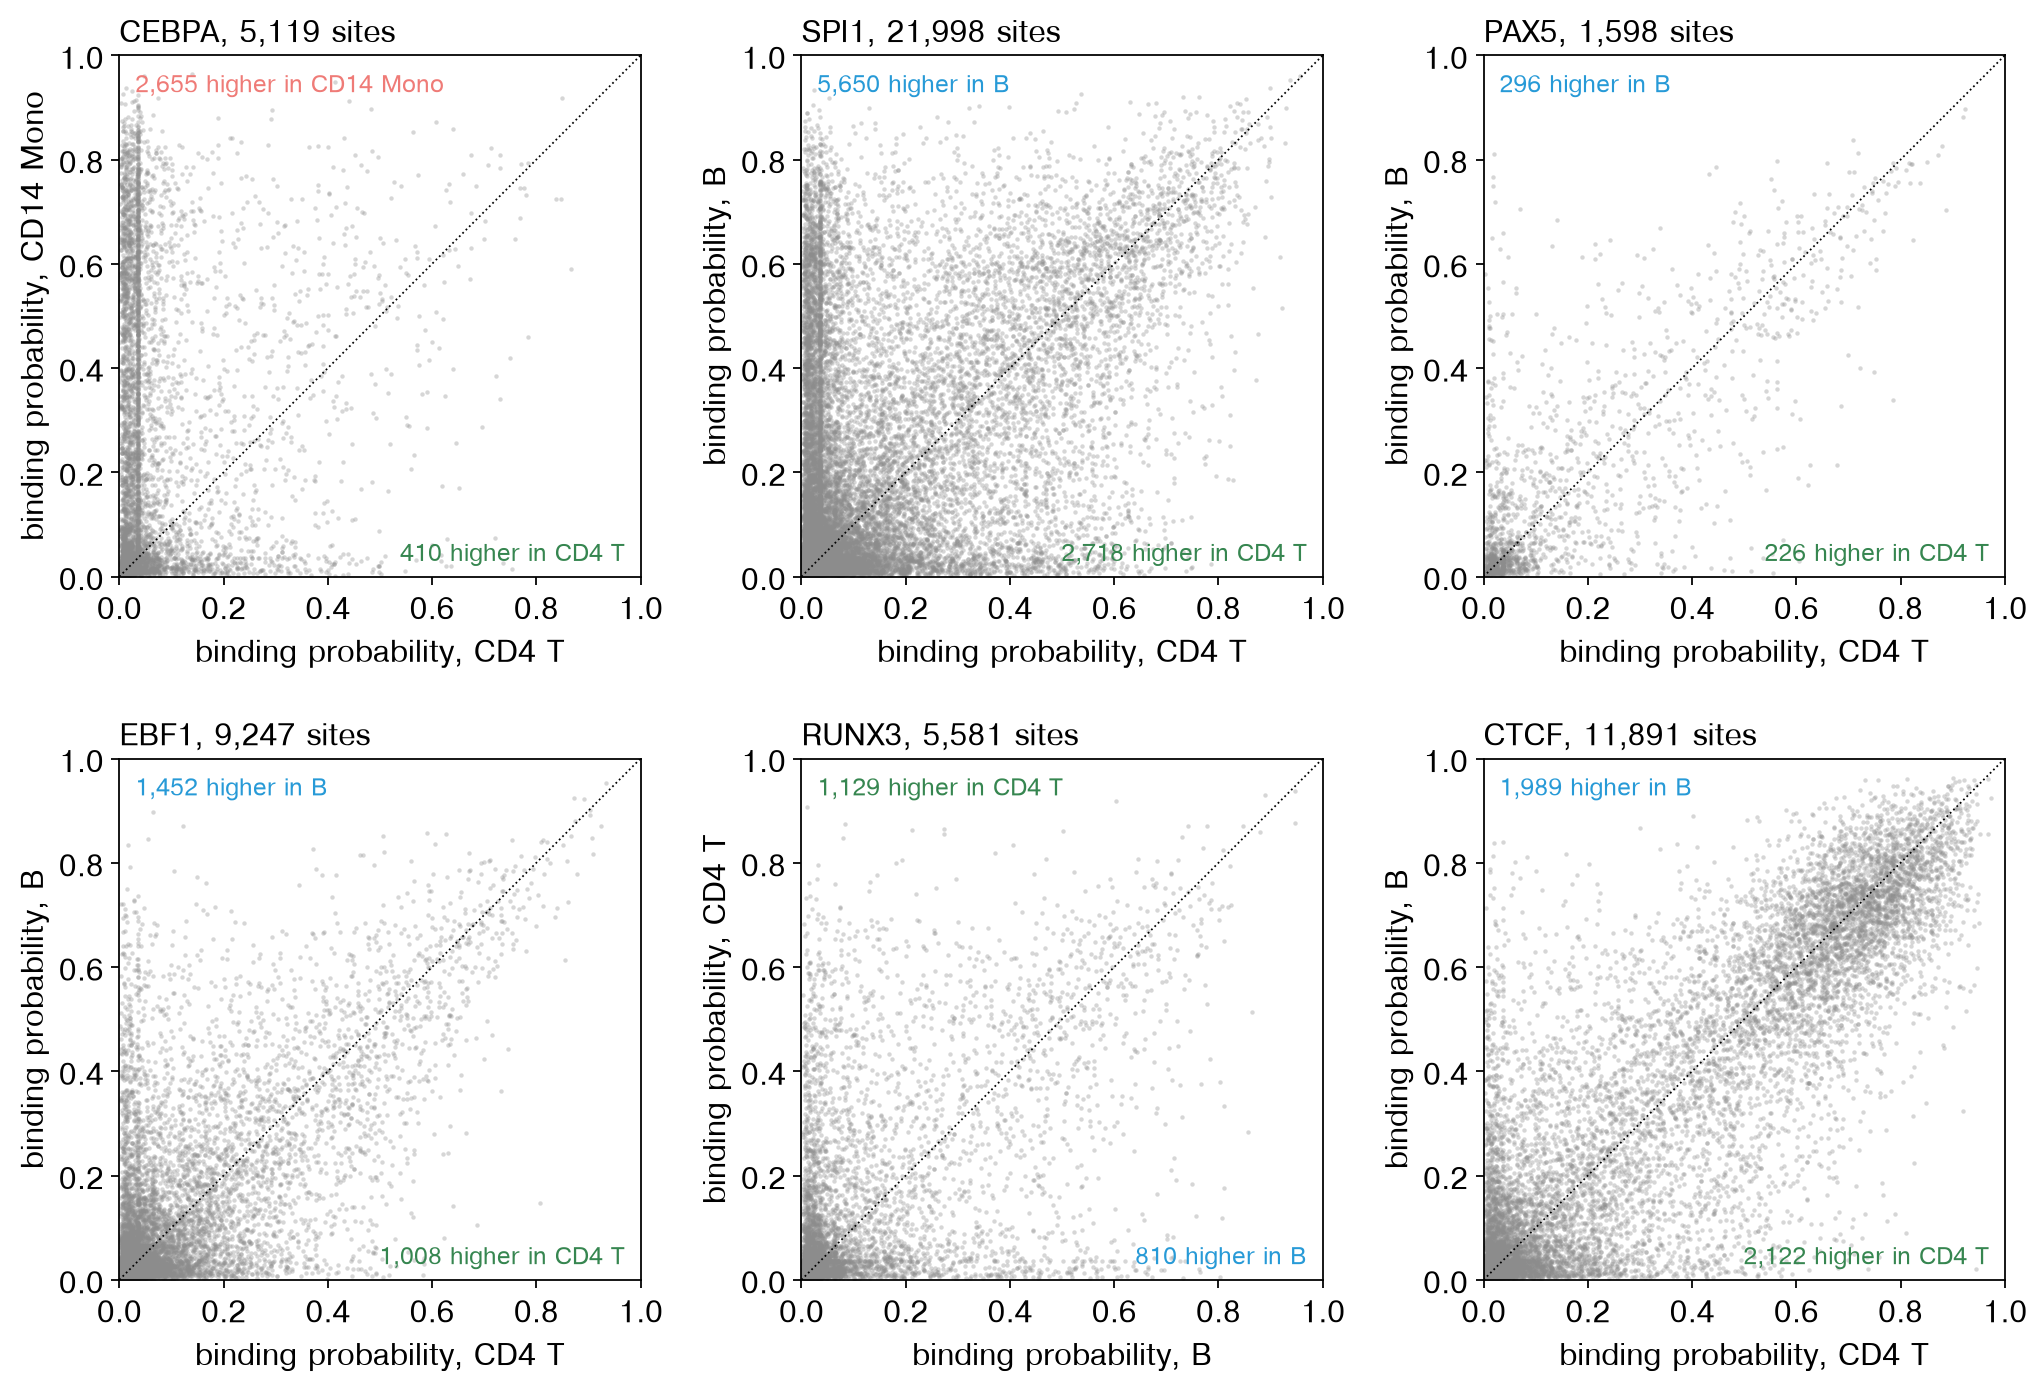

,y,x,sites,% higher in y,% higher in x,mean y − x
TF,,,,,,
CEBPA,CD14 Mono,CD4 T,5119,52,8,0.210
SPI1,B,CD4 T,21998,26,12,0.054
PAX5,B,CD4 T,1598,19,14,0.013
EBF1,B,CD4 T,9247,16,11,0.018
RUNX3,CD4 T,B,5581,20,15,0.019
CTCF,B,CD4 T,11891,17,18,-0.002


In [13]:
PAIRS = [('CEBPA', 'CD14 Mono', 'CD4 T'), ('SPI1', 'B', 'CD4 T'), ('PAX5', 'B', 'CD4 T'),
         ('EBF1', 'B', 'CD4 T'), ('RUNX3', 'CD4 T', 'B'), ('CTCF', 'B', 'CD4 T')]

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
rows = []
for ax, (tf, gy, gx) in zip(axes.flat, PAIRS):
    d = sites[sites.name == tf]
    diff = d[gy] - d[gx]
    up, down = (diff > 0.1).sum(), (diff < -0.1).sum()
    ax.scatter(d[gx], d[gy], s=4, color='0.55', alpha=0.35, lw=0, rasterized=True)
    ax.plot([0, 1], [0, 1], color='k', lw=0.8, ls=':')
    ax.text(0.03, 0.97, f'{up:,} higher in {gy}', transform=ax.transAxes, va='top',
            fontsize=11, color=COLOR[gy])
    ax.text(0.97, 0.03, f'{down:,} higher in {gx}', transform=ax.transAxes, ha='right',
            fontsize=11, color=COLOR[gx])
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect('equal'); ax.grid(False)
    ax.set_xlabel(f'binding probability, {gx}'); ax.set_ylabel(f'binding probability, {gy}')
    ax.set_title(f'{tf}, {len(d):,} sites', loc='left')
    rows.append({'TF': tf, 'y': gy, 'x': gx, 'sites': len(d),
                 '% higher in y': round(100 * up / len(d)), '% higher in x': round(100 * down / len(d)),
                 'mean y − x': round(diff.mean(), 3)})
plt.tight_layout(); plt.show()
compare = pd.DataFrame(rows).set_index('TF')
compare

Reading the panels:

* **CEBPA** is the clearest case. 52% of its sites score higher in CD14
  monocytes and 8% higher in CD4 T cells, as in scPrinter's tutorial. The
  vertical line of dots at 0.036 is sites with no footprint in T cells.
* **SPI1 (PU.1)** sites score higher in B cells than in CD4 T cells at 26%
  of sites and lower at 12%. B cells express PU.1 and T cells do not.
* **CTCF**, the control, is symmetric: 17% of sites higher in B cells, 18%
  higher in CD4 T cells. This is the spread to expect for a factor bound in
  both types, from sampling noise and real site-to-site differences.
* **PAX5, EBF1 and RUNX3** lean the expected way, but only a little beyond
  the CTCF spread: PAX5 and EBF1 sites score higher in B cells at 19% and
  16% of sites (14% and 11% the other way), RUNX3 sites higher in CD4 T
  cells at 20% (15% the other way). Their mean differences are 0.01-0.02.

Why these three are hard to read, and what to keep in mind for any factor:

* PRINT measures a footprint. A factor that binds briefly or protects
  little DNA leaves a weak one, and its scores stay near the floor. scPrinter's
  tutorial makes the same point: binding of such factors is underpowered.
* Few sites make a noisy comparison. PAX5 has the fewest here (1,598).
* Factors of one family share motifs. A RUNX motif can be bound by RUNX1 as
  well as RUNX3, and SPI1's ETS motif by other ETS factors. The score belongs
  to the site, not to the factor named after the motif. The PAX5 sites that
  score high in monocytes point the same way.
* A score mixes footprint and accessibility. A site in a region that is
  closed in one cell type has too few cuts to show a footprint there and
  gets the floor value.
* Scores rise with depth, so compare pseudobulks of equal depth (or check a
  control factor such as CTCF, as above).

PRINT on measured cuts therefore separates cell types well for factors with
strong footprints (CEBPA, PU.1) and gives only hints for PAX5, EBF1 and
RUNX3. As scPrinter suggests, use it to shortlist factors and sites for
follow-up rather than as a final call.

## Summary

| | |
|---|---|
| Data | 10x PBMC 10k Multiome ATAC, seven cell types from Seurat-WNN labels (`epi.datasets.pbmc10k_multiome_atac`) |
| Tn5 bias | `epi.tl.tn5_bias(genome)`: PRINT's CNN, run on the bases asked for |
| Footprints at a locus | `epi.tl.multi_scale_footprint_region(adata, [{'chrom', 'center', 'strand'}], groupby=..., bias=bias)` and `epi.pl.plot_multi_scale_footprint_region` |
| Binding at motif sites | `epi.tl.hint_match_motifs` for the sites, then `epi.tl.tf_binding_score(..., sites=...)` → `TFBindingResult` (`.score`, `.sites`, `.to_frame()`) |
| What we saw | marker promoters are open and footprinted in the cell type that expresses the gene, and related types share the same nucleosome-sized footprints (SPI1 in monocytes and B cells, CD3D in CD4 and CD8 T cells). At equal depth, CEBPA sites are footprinted in monocytes (52% of sites higher than in CD4 T cells, 8% lower) and SPI1 sites more in B than in T cells (26% vs 12%); the CTCF control is symmetric (17% vs 18%); PAX5, EBF1 and RUNX3 differ only slightly |
| Limits | needs deep pseudobulks (hundreds of cuts per window); scores rise with depth, so compare at equal depth; a score mixes accessibility with footprint shape; motif families share sites |
| Related | [seq2PRINT](t_seq2print.ipynb) predicts footprints from sequence; [t_tf_binding](t_tf_binding.ipynb) is the default per-site binding score |